<a href="https://colab.research.google.com/github/Renyambar/PCVK26_23_Reny/blob/main/Week7_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##D. TUGAS PRAKTIKUM
###D1. Tugas Individu

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

**Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold= 200, secara manual**

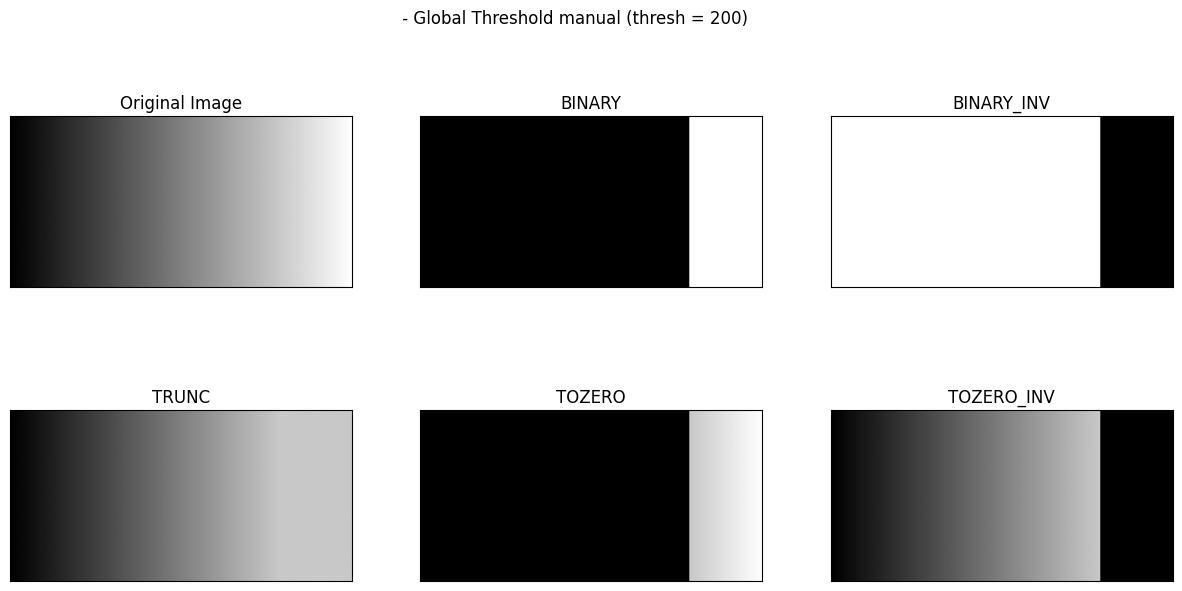

In [ ]:
# Membuat citra gradasi 400 x 200 sendiri (gelap di kiri, terang di kanan)
lebar, tinggi = 400, 200
satu_baris = np.linspace(0, 255, lebar).astype(np.uint8)      # 0 sampai 255 dari kiri ke kanan
gradient = np.tile(satu_baris, (tinggi, 1))                   # diulang untuk semua baris

thresh = 200
maxVal = 255

# Dibuat manual dengan NumPy, mengikuti rumus persis seperti di modul
binary      = np.where(gradient > thresh, maxVal, 0).astype(np.uint8)
binary_inv  = np.where(gradient > thresh, 0, maxVal).astype(np.uint8)
trunc       = np.where(gradient > thresh, thresh, gradient).astype(np.uint8)
tozero      = np.where(gradient > thresh, gradient, 0).astype(np.uint8)
tozero_inv  = np.where(gradient > thresh, 0, gradient).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [gradient, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 7))
plt.suptitle(' - Global Threshold manual (thresh = 200)')
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()


In [ ]:
# Pembuktian: hasil manual kita dibandingkan dengan cv.threshold bawaan OpenCV
ret, cv_binary     = cv.threshold(gradient, thresh, maxVal, cv.THRESH_BINARY)
ret, cv_binary_inv = cv.threshold(gradient, thresh, maxVal, cv.THRESH_BINARY_INV)
ret, cv_trunc      = cv.threshold(gradient, thresh, maxVal, cv.THRESH_TRUNC)
ret, cv_tozero     = cv.threshold(gradient, thresh, maxVal, cv.THRESH_TOZERO)
ret, cv_tozero_inv = cv.threshold(gradient, thresh, maxVal, cv.THRESH_TOZERO_INV)

print('Selisih BINARY     :', np.max(np.abs(binary.astype(int)     - cv_binary.astype(int))))
print('Selisih BINARY_INV :', np.max(np.abs(binary_inv.astype(int) - cv_binary_inv.astype(int))))
print('Selisih TRUNC       :', np.max(np.abs(trunc.astype(int)      - cv_trunc.astype(int))))
print('Selisih TOZERO      :', np.max(np.abs(tozero.astype(int)     - cv_tozero.astype(int))))
print('Selisih TOZERO_INV  :', np.max(np.abs(tozero_inv.astype(int) - cv_tozero_inv.astype(int))))


Selisih BINARY     : 0
Selisih BINARY_INV : 0
Selisih TRUNC       : 0
Selisih TOZERO      : 0
Selisih TOZERO_INV  : 0


**Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata. Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 × 11, C=2, dan sigma=2 untuk Gaussian**

In [ ]:
def adaptive_mean(gray, blockSize, C):
    """Menghitung ambang lokal T(x,y) = rata-rata jendela (blockSize x blockSize) - C"""
    pad = blockSize // 2
    # tambahkan bingkai dengan menyalin piksel pinggir, supaya tepi citra tetap bisa dihitung
    padded = cv.copyMakeBorder(gray, pad, pad, pad, pad, cv.BORDER_REPLICATE)
    kernel_rata2 = np.ones((blockSize, blockSize), np.float32) / (blockSize * blockSize)
    # filter2D di sini HANYA dipakai untuk menghitung rata-rata jendela, bukan fungsi threshold
    rata2 = cv.filter2D(padded.astype(np.float32), -1, kernel_rata2)
    rata2 = rata2[pad:-pad, pad:-pad]       # buang bingkai supaya ukuran balik seperti semula
    return rata2 - C

def adaptive_gaussian(gray, blockSize, C, sigma):
    pad = blockSize // 2
    padded = cv.copyMakeBorder(gray, pad, pad, pad, pad, cv.BORDER_REPLICATE)
    kernel_1d = cv.getGaussianKernel(blockSize, sigma)   # kernel Gaussian 1 dimensi
    kernel_2d = kernel_1d @ kernel_1d.T                  # dijadikan 2 dimensi
    rata2 = cv.filter2D(padded.astype(np.float32), -1, kernel_2d.astype(np.float32))
    rata2 = rata2[pad:-pad, pad:-pad]
    return rata2 - C

def adaptive_threshold_manual(gray, blockSize, C, metode, sigma=2):
    if metode == 'mean':
        T = adaptive_mean(gray, blockSize, C)
    else:
        T = adaptive_gaussian(gray, blockSize, C, sigma)
    # langkah 5 pada modul: piksel > T menjadi putih, selain itu hitam
    hasil = np.where(gray.astype(np.float32) > T, 255, 0).astype(np.uint8)
    return hasil


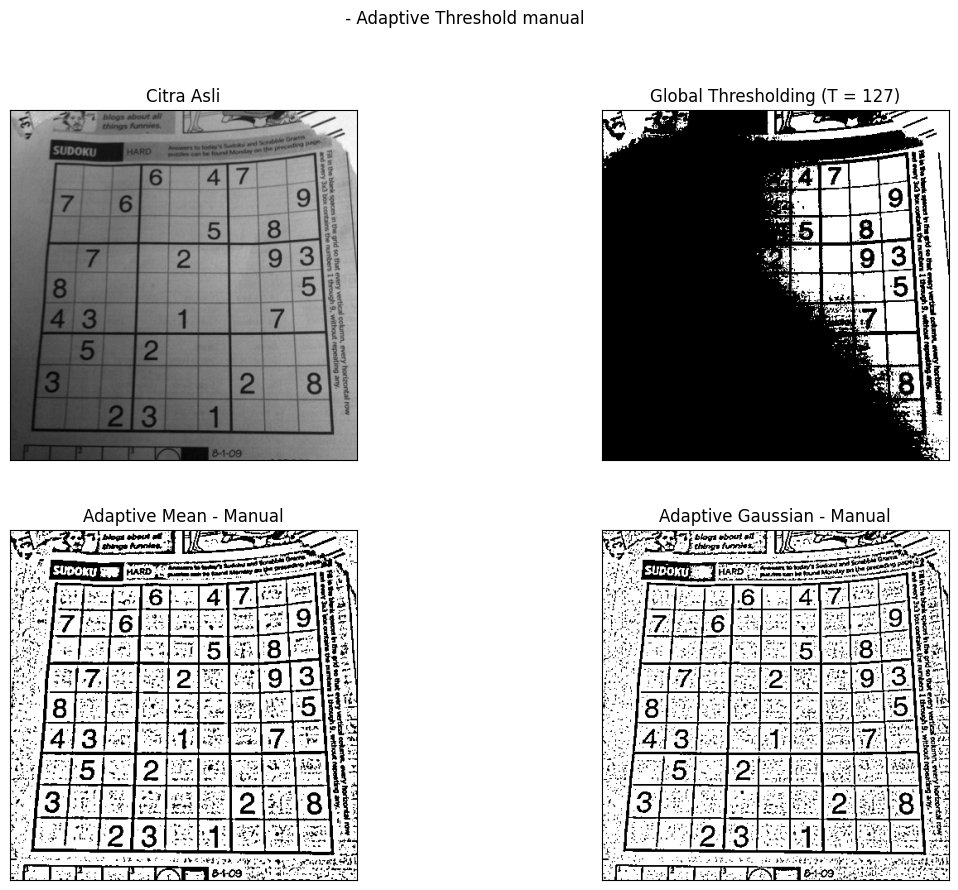

In [17]:
citra = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/sudoku-original.jpg')
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127
blockSize = 11
C = 2
sigma = 2

# Global threshold manual (ambang tetap 127 untuk semua piksel)
th_global = np.where(gray > thresh, 255, 0).astype(np.uint8)

# Adaptive threshold manual (ambang berbeda tiap piksel)
th_mean     = adaptive_threshold_manual(gray, blockSize, C, 'mean')
th_gaussian = adaptive_threshold_manual(gray, blockSize, C, 'gaussian', sigma)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
citra2 = [gray, th_global, th_mean, th_gaussian]

plt.figure(figsize=(14, 10))
plt.suptitle(' - Adaptive Threshold manual')
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()


In [18]:
# Pembuktian: dibandingkan dengan cv.adaptiveThreshold bawaan OpenCV
cv_mean     = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, blockSize, C)
cv_gaussian = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, blockSize, C)

beda_mean     = np.sum(th_mean != cv_mean)
beda_gaussian = np.sum(th_gaussian != cv_gaussian)
print('Jumlah piksel berbeda (Mean)     :', beda_mean, 'dari', gray.size, 'piksel (%.2f%%)' % (100*beda_mean/gray.size))
print('Jumlah piksel berbeda (Gaussian) :', beda_gaussian, 'dari', gray.size, 'piksel (%.2f%%)' % (100*beda_gaussian/gray.size))


Jumlah piksel berbeda (Mean)     : 4213 dari 177237 piksel (2.38%)
Jumlah piksel berbeda (Gaussian) : 5224 dari 177237 piksel (2.95%)



**A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library.**

In [21]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        t = int(t)
        pcb = np.sum(his[:t])     # jumlah piksel kelompok gelap (background)
        pcf = np.sum(his[t:])     # jumlah piksel kelompok terang (foreground)
        if pcb == 0 or pcf == 0:
            continue              # lewati t yang membuat salah satu kelompok kosong

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        # Between-class variance; t dengan nilai TERBESAR dipilih (setara within-class variance TERKECIL)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh



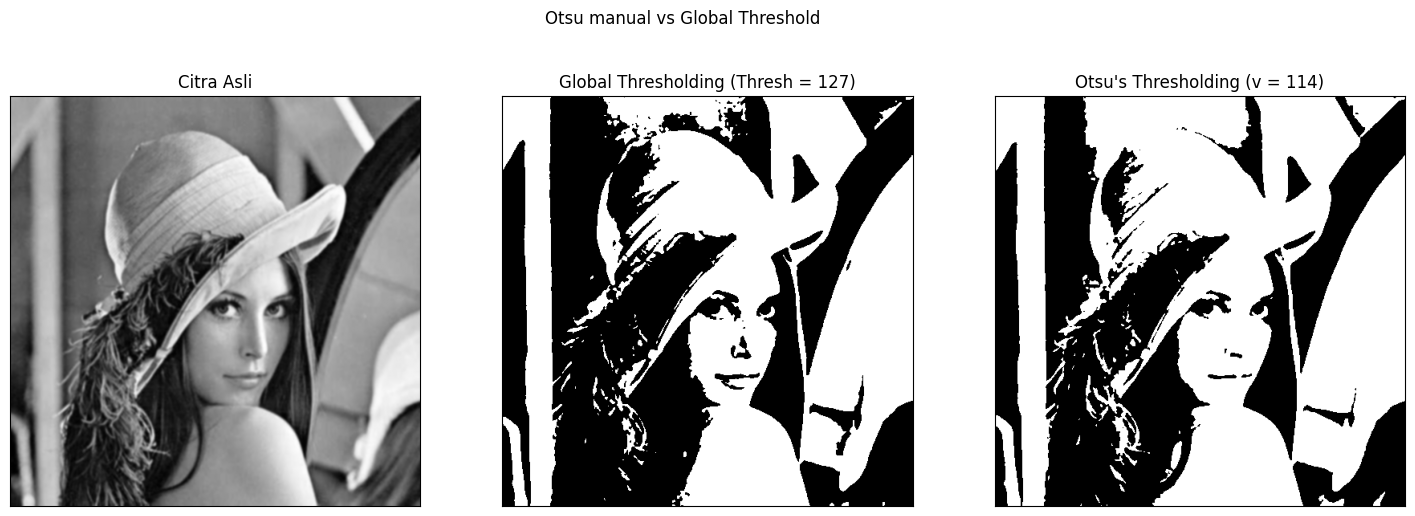

Threshold hasil manual : 114
Threshold hasil cv2    : 113.0
Selisih jumlah piksel  : 1197 dari 262144 piksel


In [23]:
# ---------- A. Uji pada lena_gs_lc2.jpg, dibandingkan dengan Otsu bawaan OpenCV ----------
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu_manual(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(18, 6))
plt.suptitle('Otsu manual vs Global Threshold ')
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()

# Pembuktian dengan Otsu bawaan OpenCV
ret_cv, otsu_cv = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Threshold hasil manual :', otsu_thresh)
print('Threshold hasil cv2    :', ret_cv)
print('Selisih jumlah piksel  :', np.sum(otsu_biner != otsu_cv), 'dari', blur.size, 'piksel')


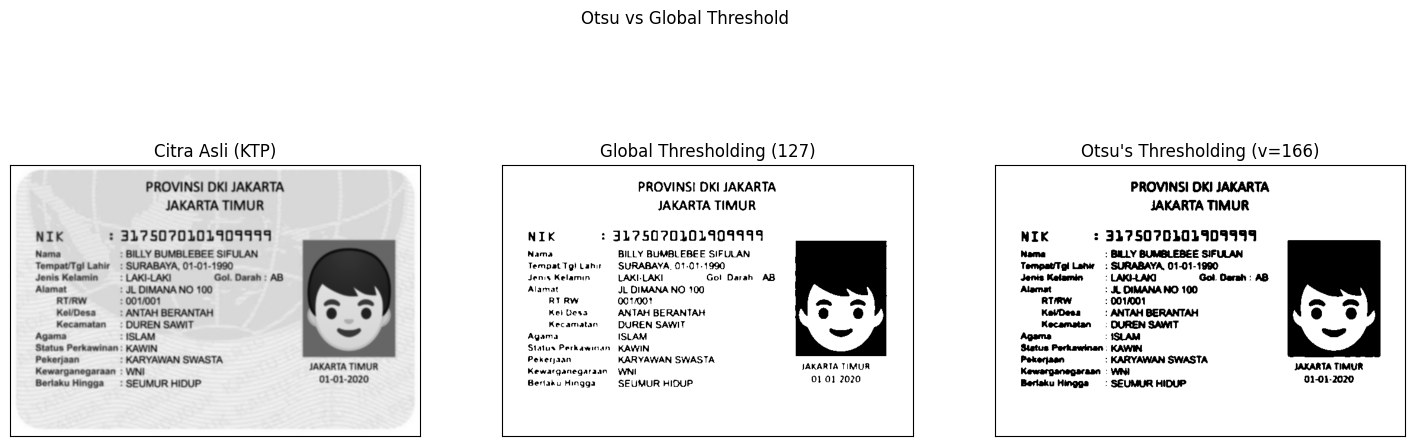

In [25]:
# ---------- B. Uji pada citra KTP/KTM sendiri ----------
img_ktp = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/ktp_fulan.jpg')
img_ktp = cv.cvtColor(img_ktp, cv.COLOR_BGR2GRAY)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)
otsu_biner_ktp, otsu_thresh_ktp = otsu_manual(blur_ktp)
ret, global_ktp = cv.threshold(blur_ktp, 127, 255, cv.THRESH_BINARY)

titles = ['Citra Asli (KTP)', 'Global Thresholding (127)', "Otsu's Thresholding (v=" + str(otsu_thresh_ktp) + ')']
citra_ktp = [blur_ktp, global_ktp, otsu_biner_ktp]

plt.figure(figsize=(18, 6))
plt.suptitle('Otsu vs Global Threshold')
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()


###Segmentasi Berbasis Wilayah (Region Growing)

**A. Region Growing buatan sendiri**, memakai 3 seed (dalam koin, di latar, di tepi koin) dan 3 nilai `T` (5, 20, 60).

In [26]:
def region_growing(gray, seed, T):
    """Region growing sederhana dengan BFS (antrean), kriteria: |nilai piksel - nilai seed| < T.
    seed berupa (baris, kolom)."""
    H, W = gray.shape
    gray_f = gray.astype(np.float64)
    visited = np.zeros((H, W), dtype=bool)
    mask = np.zeros((H, W), dtype=np.uint8)

    nilai_seed = gray_f[seed]
    antrean = deque([seed])
    visited[seed] = True

    while antrean:
        y, x = antrean.popleft()
        mask[y, x] = 255
        # cek 4 tetangga: atas, bawah, kiri, kanan
        for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not visited[ny, nx]:
                if abs(gray_f[ny, nx] - nilai_seed) < T:
                    visited[ny, nx] = True
                    antrean.append((ny, nx))
    return mask


Ukuran citra coins: (303, 384)
Seed Dalam koin (baris, kolom): (36, 43) | intensitas: 159


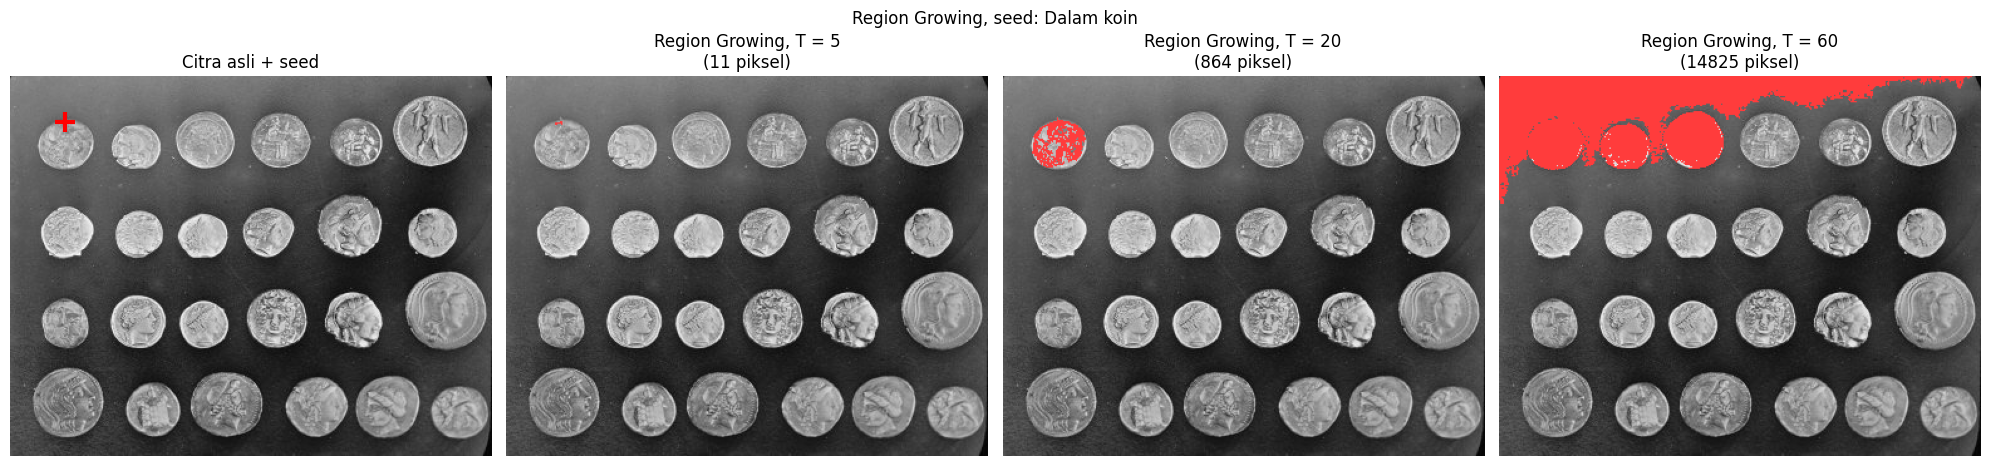

Seed Latar (baris, kolom): (20, 20) | intensitas: 123


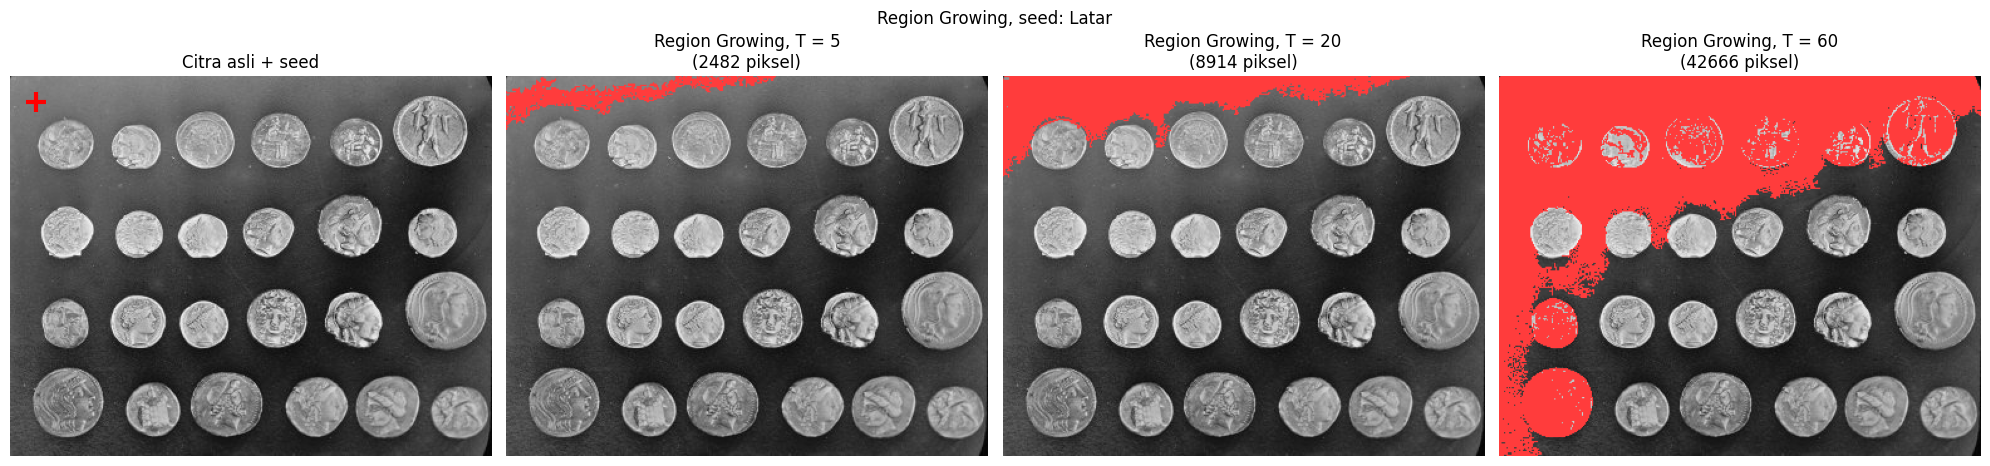

Seed Tepi koin (baris, kolom): (46, 58) | intensitas: 164


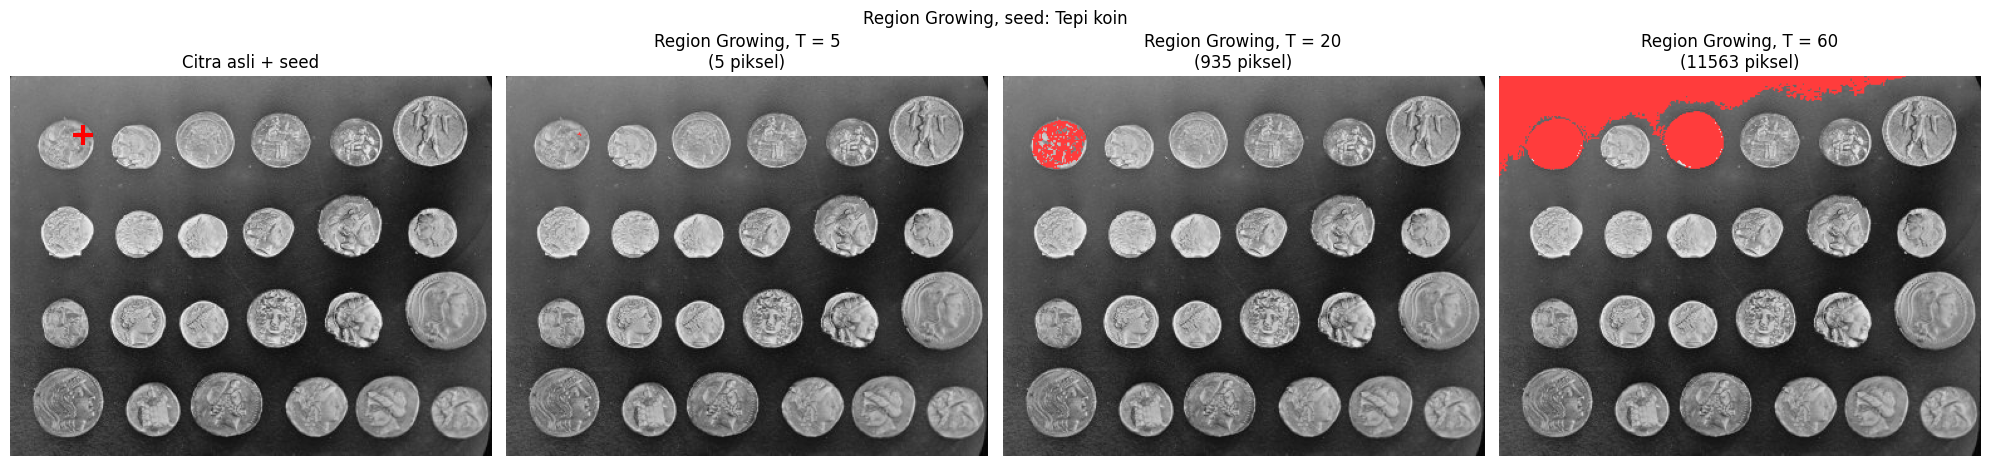

In [28]:
gray_coins = data.coins()     # grayscale, 303 x 384
print('Ukuran citra coins:', gray_coins.shape)

# tiga seed: di dalam koin, di latar, dan di tepi koin (baris, kolom)
# silakan sesuaikan koordinat ini kalau ingin mencoba posisi lain
seed_dalam_koin = (36, 43)
seed_latar       = (20, 20)
seed_tepi_koin    = (46, 58)
seeds = {'Dalam koin': seed_dalam_koin, 'Latar': seed_latar, 'Tepi koin': seed_tepi_koin}

nilai_T = [5, 20, 60]

for nama_seed, posisi in seeds.items():
    print('Seed', nama_seed, '(baris, kolom):', posisi, '| intensitas:', gray_coins[posisi])

    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle('Region Growing, seed: ' + nama_seed)

    # panel 1: citra asli + tanda seed
    axs[0].imshow(gray_coins, cmap='gray')
    axs[0].plot(posisi[1], posisi[0], 'r+', markersize=15, markeredgewidth=3)
    axs[0].set_title('Citra asli + seed')
    axs[0].axis('off')

    # panel 2-4: hasil region growing untuk tiap T
    for i, T in enumerate(nilai_T):
        mask = region_growing(gray_coins, posisi, T)
        jumlah_piksel = np.sum(mask == 255)

        tampilan = cv.cvtColor(gray_coins, cv.COLOR_GRAY2RGB)
        tampilan[mask == 255] = [255, 60, 60]     # beri warna merah pada region hasil

        axs[i + 1].imshow(tampilan)
        axs[i + 1].set_title(f'Region Growing, T = {T}\n({jumlah_piksel} piksel)')
        axs[i + 1].axis('off')

    plt.tight_layout()
    plt.show()


Seed (baris, kolom): (121, 63) | intensitas: 224
Toleransi 5 : 19 piksel
Toleransi 20 : 177 piksel
Toleransi 60 : 1151 piksel


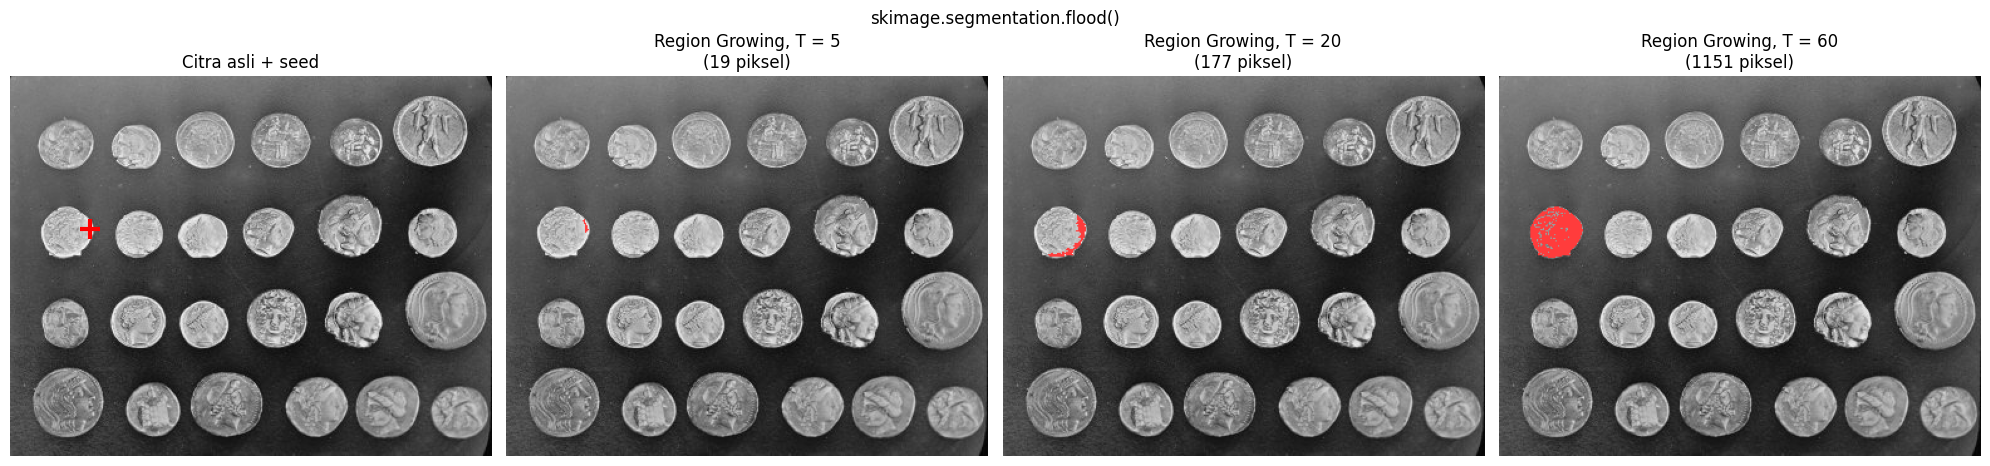

In [30]:
seed_flood = (121, 63)

print('Seed (baris, kolom):', seed_flood, '| intensitas:', gray_coins[seed_flood])

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('skimage.segmentation.flood()')

axs[0].imshow(gray_coins, cmap='gray')
axs[0].plot(seed_flood[1], seed_flood[0], 'r+', markersize=15, markeredgewidth=3)
axs[0].set_title('Citra asli + seed')
axs[0].axis('off')

for i, T in enumerate(nilai_T):
    region = flood(gray_coins, seed_point=seed_flood, tolerance=T, connectivity=1)   # 4 tetangga untuk citra 2D
    jumlah_piksel = np.sum(region)
    print('Toleransi', T, ':', jumlah_piksel, 'piksel')

    tampilan = cv.cvtColor(gray_coins, cv.COLOR_GRAY2RGB)
    tampilan[region] = [255, 60, 60]

    axs[i + 1].imshow(tampilan)
    axs[i + 1].set_title(f'Region Growing, T = {T}\n({jumlah_piksel} piksel)')
    axs[i + 1].axis('off')

plt.tight_layout()
plt.show()


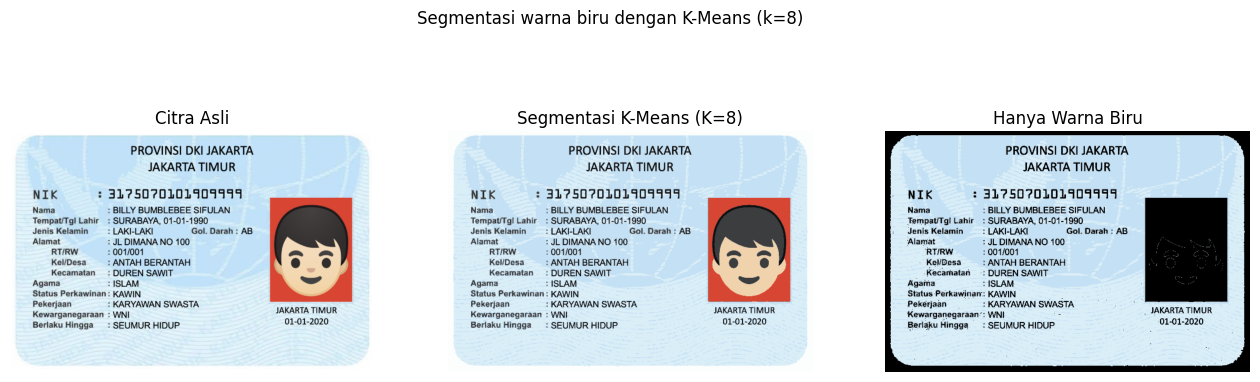

In [36]:
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/PCVK /Image Jobsheet/ktp_fulan.jpg'     # ganti dengan nama citra KTP/KTM milikmu kalau berbeda
img = cv.imread(filename)
if img is None:
    # citra pengganti: kotak biru di tengah latar putih, supaya kode tetap bisa dicoba
    img = np.full((200, 300, 3), 255, dtype=np.uint8)   # BGR putih
    img[40:160, 30:150] = (200, 120, 40)                 # kotak biru (format BGR)
    img[70:130, 180:270] = (100, 180, 230)                # kotak oranye, sebagai pembanding

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Langkah 1: K-Means untuk kuantisasi warna (mengurangi jumlah warna menjadi K kelompok)
Z = img_rgb.reshape((-1, 3)).astype(np.float32)
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img_rgb.shape)        # citra RGB, tapi hanya berisi K warna

# Langkah 2: ubah citra hasil K-Means ke HSV untuk memudahkan memilih warna biru
hsv = cv.cvtColor(cv.cvtColor(segmented_img, cv.COLOR_RGB2BGR), cv.COLOR_BGR2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

# Langkah 3: pilih piksel biru (sesuai petunjuk pada modul)
kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Langkah 4: citra hanya warna biru, selain itu dijadikan putih
hanya_biru = segmented_img.copy()
hanya_biru[~kelompok_biru] = [0, 0, 0]

plt.figure(figsize=(16, 5))
plt.suptitle('Segmentasi warna biru dengan K-Means (k=' + str(k) + ')')
plt.subplot(1, 3, 1); plt.imshow(img_rgb); plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(segmented_img); plt.title('Segmentasi K-Means (K=' + str(k) + ')'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(hanya_biru); plt.title('Hanya Warna Biru'); plt.axis('off')
plt.show()


In [37]:
# Instalasi Tesseract OCR
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [38]:
import pytesseract
from pytesseract import Output

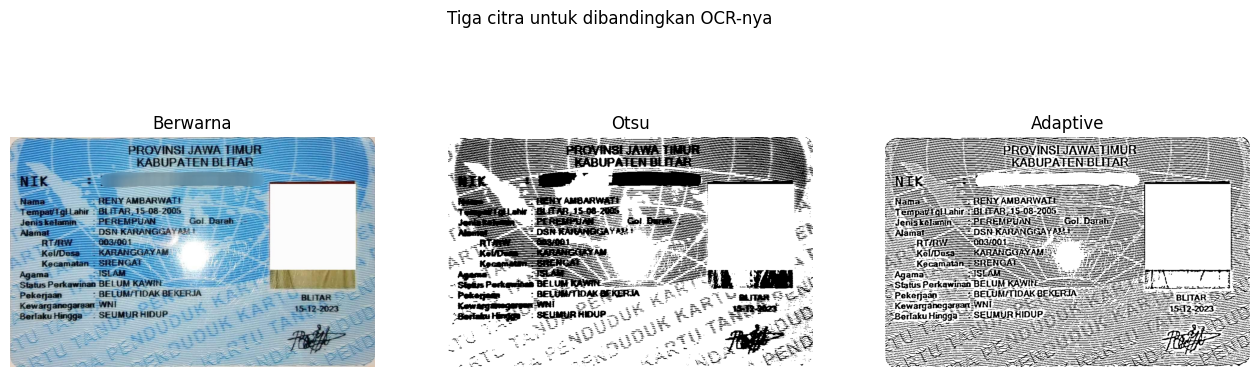

In [44]:
# ----- Langkah 1: siapkan tiga citra untuk dibandingkan -----
ktp_reny = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/ktp_reny.jpeg')
gray_ktp = cv.cvtColor(ktp_reny, cv.COLOR_BGR2GRAY)

blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)
ret, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv.THRESH_BINARY, 25, 10)

judul = ['Berwarna', 'Otsu', 'Adaptive']
citra_uji = [cv.cvtColor(ktp_reny, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

plt.figure(figsize=(16, 5))
plt.suptitle('Tiga citra untuk dibandingkan OCR-nya')
for i in range(3):
    plt.subplot(1, 3, i + 1)
    cmap = None if i == 0 else 'gray'
    plt.imshow(citra_uji[i], cmap=cmap)
    plt.title(judul[i])
    plt.axis('off')
plt.show()


In [45]:
# ----- Langkah 2: pembacaan teks dengan pytesseract.image_to_string() -----
konfigurasi = '--psm 6'
bahasa = 'ind'

hasil_teks = {}
for nama, citra in zip(judul, citra_uji):
    teks = pytesseract.image_to_string(citra, lang=bahasa, config=konfigurasi)
    hasil_teks[nama] = teks
    print('=' * 10, nama, '=' * 10)
    print(teks)
    print()


========== Berwarna ==========
5—cee #1. cw zr -
5Z-—e AAA AA
—:—e-: —5— DAY I NS“ A NYA —- —
5 — ABU AE BE AR
aa Pa ee aa AA
— JP 5 ——— 2 5 — 5
5—.—— —— 3 —————-
— — 5 |—————
— ——— To ——— FP
JT &&L&&& 55 ——
we Pr 5 -
— Nama — — —HENYAMBARWATE- —————— Te
——ws-—————— A5 —.—
STempargi Lahi SBL PFAR 15-03-2005 3 ——
Pa — me wi —
jera — PEREMPUAN ——— Gol Darah —
aa ea aa wwe -
—J5—— — ——ew —
Alama— — “DSN KARANGAY II FF
— AA 930p — 5 —
— RAM 03001 —— A5 PP
—— Kel/Dese —KARANGGAYAM Ea | PF
11 AA ES 5 FA
“Agama SAM — PE FA
A3 5 AA 2 AS
—Status Perkawinan BELUM KAWI-———.-——— 5
Pokana — BELUM DAK BEKERIA 3 ge
“Kewarganegaraan WNI 5 5. 22 2023 —
2Beriaku Hingga - SEUMURHIDUP —— 5. 55
AAA AA
SA — AA AA Le 5 5—ya
SA AK AAA AE
Ae AA 2 EA A
PA BA SP AA
5 ti AA #-w—-——6—-———
SE — RAT ———— “AK KKS Sa ——
AE AA Ae ———ara


========== Otsu ==========
- en —- —-  £
Ba SUPATENG ,
— -——— ——— AP
FI “ga ————....
—. vw — PP —— aus -
- 2 TEMENYAMBARWAEE ALI “
. N BEM Si Da —
an NE 2:
ang 5: -
Maan —3Po ot En
Pa

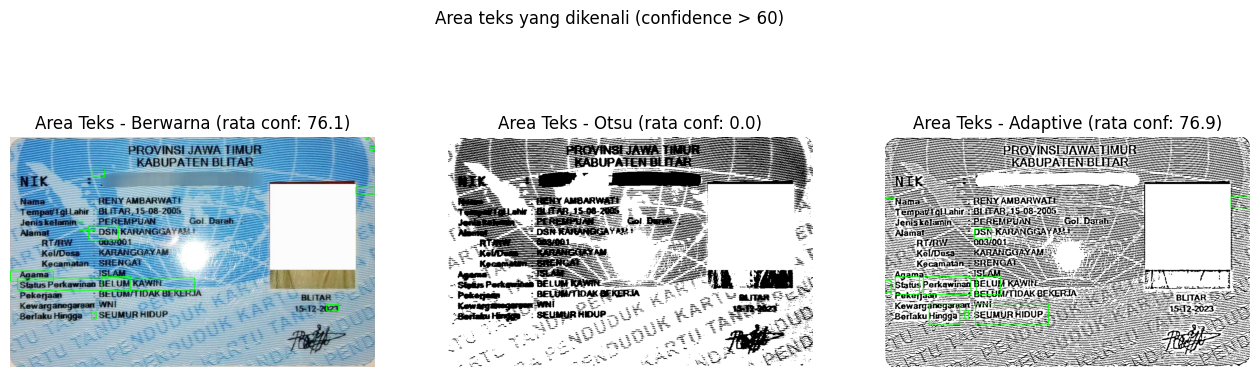

In [47]:
# ----- Langkah 3: tampilkan area teks yang dikenali dengan kotak hijau -----
def gambar_kotak_teks(citra, berwarna, confidence_min=60):
    data = pytesseract.image_to_data(citra, lang=bahasa, config=konfigurasi, output_type=Output.DICT)

    if berwarna:
        hasil = citra.copy()
    else:
        hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)

    confidence_terpakai = []
    for i in range(len(data['text'])):
        conf = int(float(data['conf'][i])) if data['conf'][i] != '-1' else -1
        if conf > confidence_min and data['text'][i].strip() != '':
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
            confidence_terpakai.append(conf)
    return hasil, confidence_terpakai

batas_confidence = 60
hasil_kotak = {}
rata_confidence = {}
for nama, citra, berwarna in zip(judul, citra_uji, [True, False, False]):
    citra_asli_format = ktp_reny if nama == 'Berwarna' else citra
    kotak, conf_list = gambar_kotak_teks(citra_asli_format, berwarna=(nama == 'Berwarna'), confidence_min=batas_confidence)
    hasil_kotak[nama] = kotak
    rata_confidence[nama] = np.mean(conf_list) if len(conf_list) > 0 else 0

plt.figure(figsize=(16, 5))
plt.suptitle('Area teks yang dikenali (confidence > ' + str(batas_confidence) + ')')
for i, nama in enumerate(judul):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(hasil_kotak[nama], cv.COLOR_BGR2RGB))
    plt.title('Area Teks - ' + nama + f' (rata conf: {rata_confidence[nama]:.1f})')
    plt.axis('off')
plt.show()


In [48]:
acuan = [
    'PROVINSI', 'NIK', 'Nama', 'Tempat', 'Jenis Kelamin',
    'Alamat', 'Agama', 'Pekerjaan', 'Kewarganegaraan', 'WNI',
]

def bersihkan(teks):
    return teks.strip().lower()

def cek_kecocokan(daftar_acuan, teks_ocr):
    teks_bersih = bersihkan(teks_ocr)
    hasil = []
    for kata in daftar_acuan:
        cocok = bersihkan(kata) in teks_bersih
        hasil.append(cocok)
    return hasil

tabel_kecocokan = pd.DataFrame({'Teks sebenarnya': acuan})
for nama in judul:
    tabel_kecocokan['OCR ' + nama] = cek_kecocokan(acuan, hasil_teks[nama])

print(tabel_kecocokan)


   Teks sebenarnya  OCR Berwarna  OCR Otsu  OCR Adaptive
0         PROVINSI         False     False         False
1              NIK         False     False         False
2             Nama          True     False          True
3           Tempat         False     False         False
4    Jenis Kelamin         False     False         False
5           Alamat         False     False         False
6            Agama          True     False          True
7        Pekerjaan         False     False          True
8  Kewarganegaraan          True     False         False
9              WNI          True     False         False


In [49]:
# Ringkasan: jumlah item terbaca tepat, persentase kecocokan, dan rata-rata confidence
ringkasan = []
for nama in judul:
    jumlah_cocok = tabel_kecocokan['OCR ' + nama].sum()
    persen = jumlah_cocok / len(acuan) * 100
    ringkasan.append({
        'Citra masukan OCR': nama,
        'Item terbaca tepat': jumlah_cocok,
        'Kecocokan (%)': round(persen, 1),
        'Rata-rata confidence': round(rata_confidence[nama], 1),
    })

tabel_ringkasan = pd.DataFrame(ringkasan)
print(tabel_ringkasan)


  Citra masukan OCR  Item terbaca tepat  Kecocokan (%)  Rata-rata confidence
0          Berwarna                   4           40.0                  76.1
1              Otsu                   0            0.0                   0.0
2          Adaptive                   3           30.0                  76.9
